# Figure 8-5 — LTspice compared with the analytical model

The ideal deck is the same high-gain voltage-controlled source used for
ngspice, so LTspice and the nodal model solve the same linear network.
AC results come from the `.meas` lines and from the full sweep in the raw
file. The passband transient is a 250 kHz sine, 1 V peak, with no offset.
Gain and phase use a least-squares fit on the last 40 µs, and the `.four`
row is listed beside it.

The sketch is drawn by this study. `LTSpice/Figure_8_5_MFB_500kHz_ac.asc`
and `LTSpice/Figure_8_5_MFB_250kHz_tran.asc` are the canvases. The transient
file changes only the source, to `SINE(0 1 250k)`. An export of either
canvas can replace the sketch after the parts have been arranged.

Created with Grok Build.


In [1]:
import sys

import os
os.environ["MPLBACKEND"] = "Agg"
import matplotlib
matplotlib.use("Agg", force=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import io
from pathlib import Path
from IPython.display import display, Image

def _show(*args, **kwargs):
    buf = io.BytesIO()
    fig = plt.gcf()
    fig.savefig(buf, format="png", dpi=150, bbox_inches="tight")
    plt.close("all")
    display(Image(data=buf.getvalue()))

plt.show = _show

def _find_project_root():
    start = Path.cwd().resolve()
    named = Path("Sections/Electronics/Analog_and_Digital/OPA365_Fig85")
    candidates = [start, *start.parents, start / named]
    if start.name == "notebooks":
        candidates.insert(0, start.parent)
    for cand in candidates:
        if (cand / "mfb_design" / "__init__.py").is_file():
            return cand
    raise FileNotFoundError("mfb_design package was not found")

ROOT = _find_project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


In [2]:
from mfb_design.params import CircuitParams, ToleranceSpec

p = CircuitParams(
    R1=549.0,
    R2=1.24e3,
    R3=549.0,
    C1=1.0e-9,
    C2=150.0e-12,
    r_tol=ToleranceSpec(0.001),
    c_tol=ToleranceSpec(0.01),
)
SPICE_WORKERS = 4
N_MC_AC = 2000
N_MC_TRAN = 500
MC_SEED = 42
print(
    f"R1={p.R1:g} ohm  R2={p.R2:g} ohm  R3={p.R3:g} ohm  "
    f"C1={p.C1:g} F  C2={p.C2:g} F"
)
print(
    f"supplies {p.op.v_pos:g} V / {p.op.v_neg:g} V, "
    f"tone {p.op.f_passband_hz:g} Hz, {p.op.v_in_peak:g} V peak"
)
FIG = ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)


R1=549 ohm  R2=1240 ohm  R3=549 ohm  C1=1e-09 F  C2=1.5e-10 F
supplies 2.5 V / -2.5 V, tone 250000 Hz, 1 V peak


LTspice: available


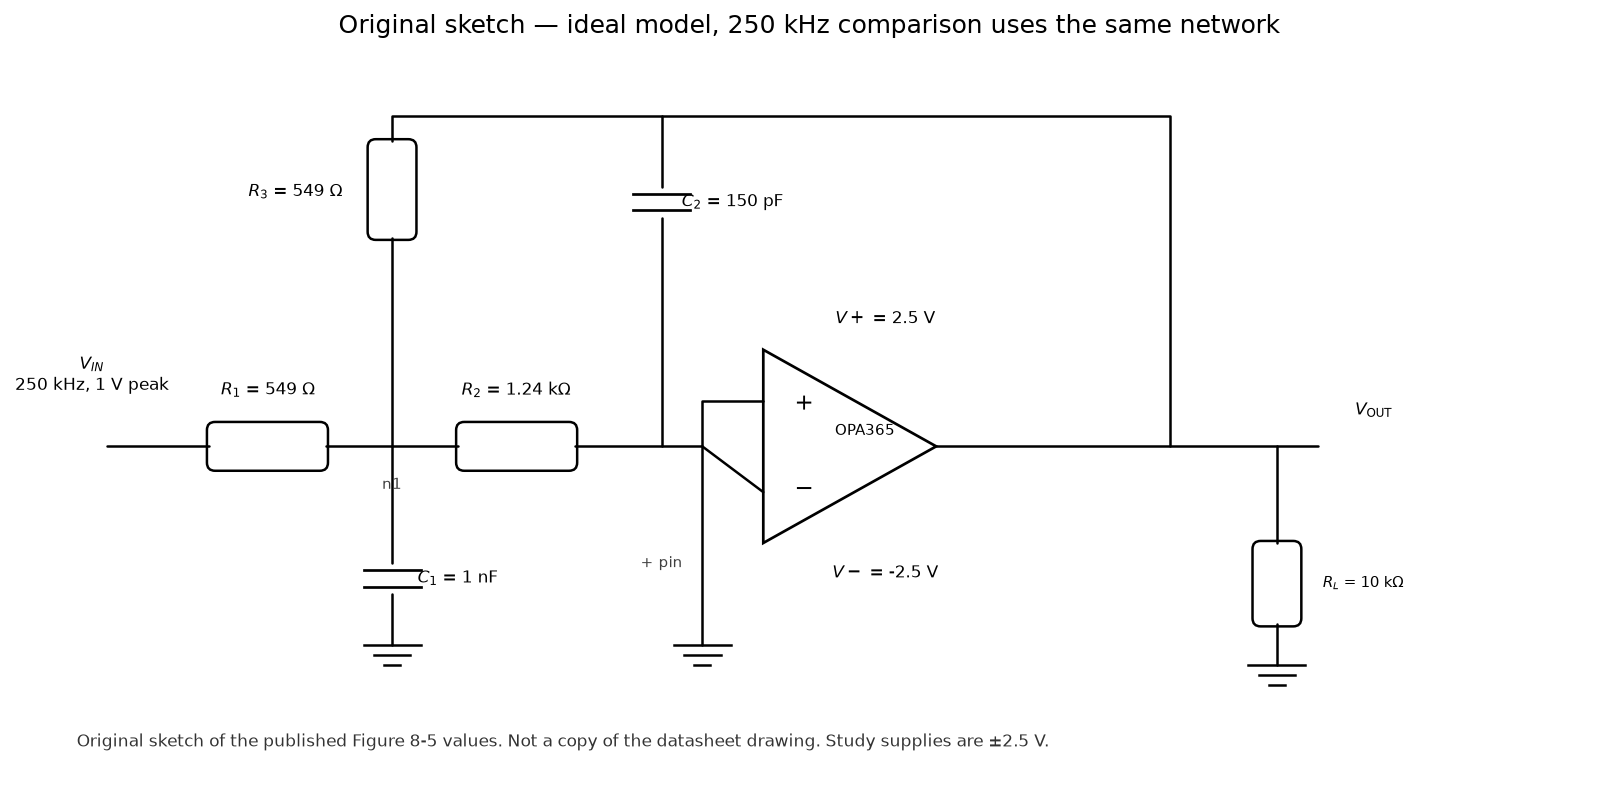

,source,fc_Hz,gain_100Hz,gain_250kHz,gain_500kHz,phase_500kHz_deg
0,analytical,495372.696835,1.000000,0.967223,0.700572,89.685913
1,LTspice ideal,495367.000000,0.999998,0.967191,0.700570,89.698314


AC points 336, max |dB error| 2.055e-05, max |phase error| 5.042e-05 deg
Analytical fc = 495372.7 Hz


In [3]:
from mfb_design.analysis import find_fc_3db, gain_at, summary_metrics
from mfb_design.ltspice_io import find_ltspice, simulate_ltspice_ac_bode
from mfb_design.schematic import draw_fig85_schematic

try:
    find_ltspice()
    print("LTspice: available")
except FileNotFoundError:
    print("LTspice: not found")
    raise

draw_fig85_schematic(
    p=p,
    title="Original sketch — ideal model, 250 kHz comparison uses the same network",
    vin_label="$V_{IN}$\n250 kHz, 1 V peak",
)
plt.show()

m_an = summary_metrics(p)
meas, lt_ac = simulate_ltspice_ac_bode(
    p,
    workdir=ROOT / "results" / "ltspice" / "nb03_ac",
    root=ROOT,
    opamp_model="ideal",
)
h_an = np.array([gain_at(p, float(f)) for f in lt_ac.f_hz])
err_db = lt_ac.mag_db - 20 * np.log10(np.maximum(np.abs(h_an), 1e-30))
phase_err = np.angle(lt_ac.h / h_an, deg=True)
rows = [
    {
        "source": "analytical",
        "fc_Hz": m_an["fc_hz"],
        "gain_100Hz": m_an["passband_gain"],
        "gain_250kHz": m_an["gain_at_passband"],
        "gain_500kHz": m_an["gain_at_fdesign"],
        "phase_500kHz_deg": m_an["phase_at_fdesign_deg"],
    },
    {
        "source": "LTspice ideal",
        "fc_Hz": meas.get("fc_3db", np.nan),
        "gain_100Hz": meas.get("gain_100hz", np.nan),
        "gain_250kHz": meas.get("gain_250k", np.nan),
        "gain_500kHz": meas.get("gain_500k", np.nan),
        "phase_500kHz_deg": meas.get("phase_500k", np.nan),
    },
]
display(pd.DataFrame(rows))
print(
    f"AC points {len(lt_ac.f_hz)}, "
    f"max |dB error| {np.max(np.abs(err_db)):.3e}, "
    f"max |phase error| {np.max(np.abs(phase_err)):.3e} deg"
)
print(f"Analytical fc = {find_fc_3db(p):.1f} Hz")
if np.max(np.abs(err_db)) > 1e-2:
    raise RuntimeError("LTspice AC disagrees with the analytical magnitude")


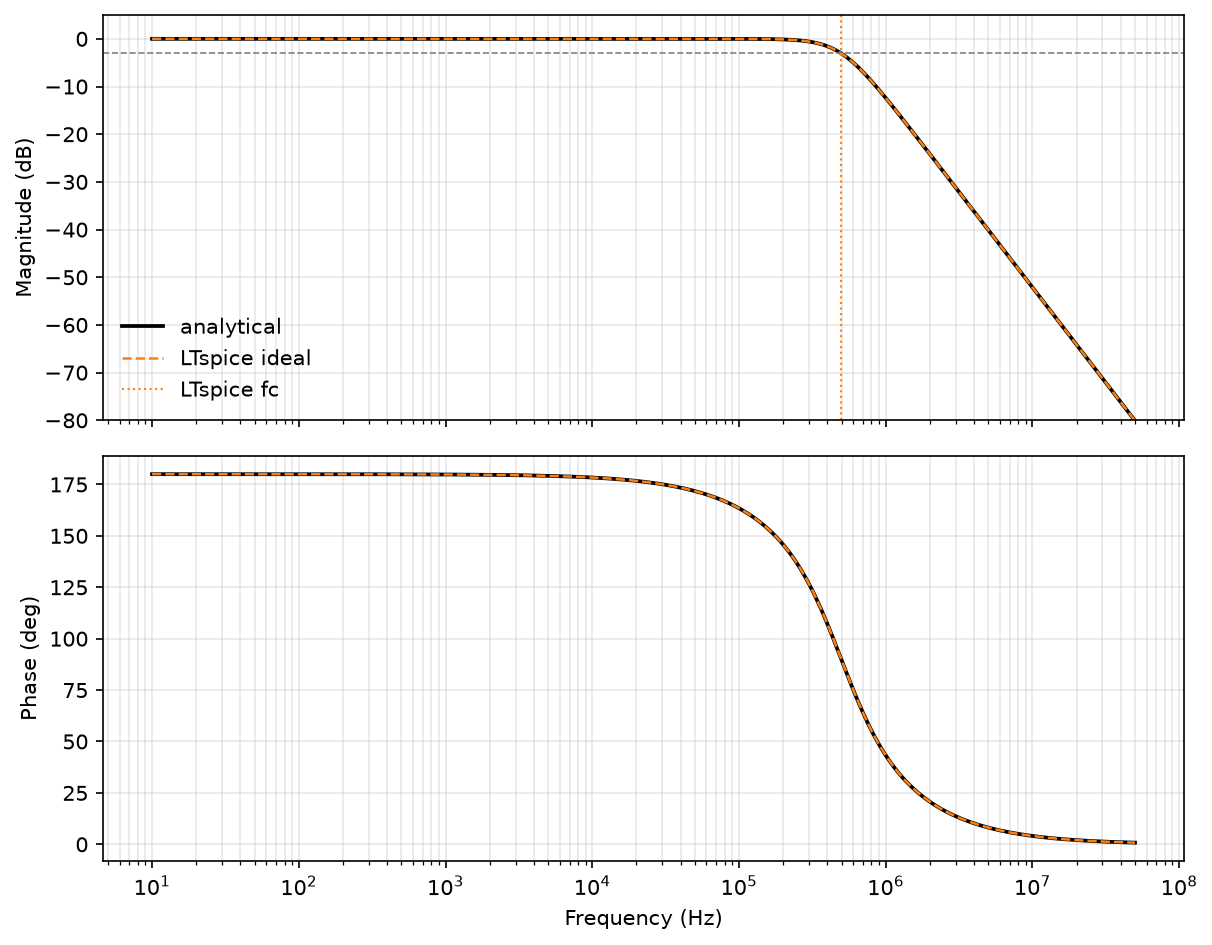

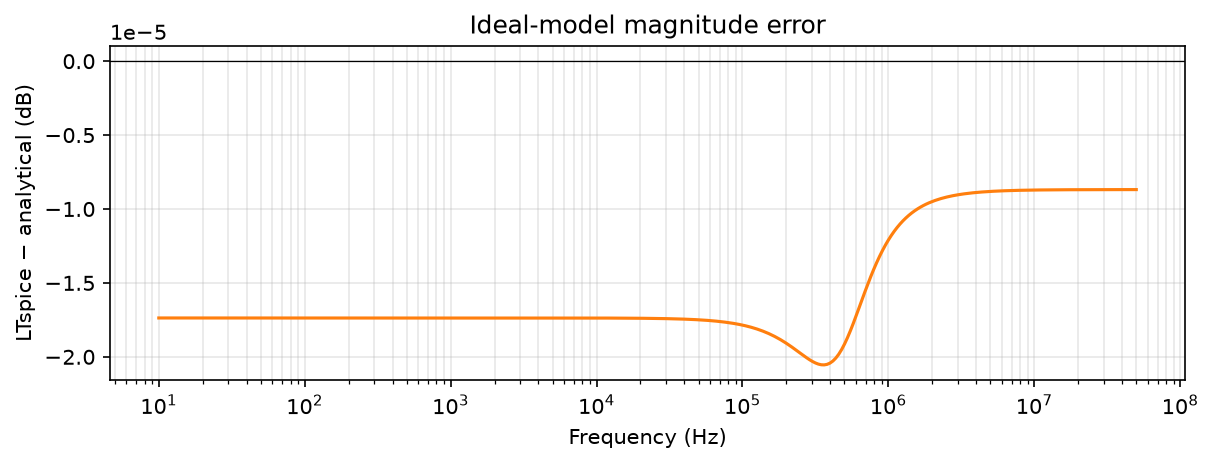

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(8.2, 6.4), sharex=True)
axes[0].semilogx(lt_ac.f_hz, 20*np.log10(np.maximum(np.abs(h_an), 1e-30)), "k-", lw=1.8, label="analytical")
axes[0].semilogx(lt_ac.f_hz, lt_ac.mag_db, "C1--", lw=1.2, label="LTspice ideal")
axes[0].axhline(-3, color="0.5", ls="--", lw=0.8)
axes[0].axvline(meas.get("fc_3db", np.nan), color="C1", ls=":", lw=1.0, label="LTspice fc")
axes[0].set_ylabel("Magnitude (dB)")
axes[0].set_ylim(-80, 5)
axes[0].grid(True, which="both", alpha=0.3)
axes[0].legend(frameon=False)
axes[1].semilogx(lt_ac.f_hz, np.rad2deg(np.unwrap(np.angle(h_an))), "k-", lw=1.8, label="analytical")
axes[1].semilogx(lt_ac.f_hz, lt_ac.phase_unwrapped_deg, "C1--", lw=1.2, label="LTspice ideal")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Phase (deg)")
axes[1].grid(True, which="both", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "03_ltspice_bode.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(8.2, 3.2))
ax.semilogx(lt_ac.f_hz, err_db, color="C1")
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("LTspice − analytical (dB)")
ax.set_title("Ideal-model magnitude error")
ax.grid(True, which="both", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "03_ltspice_error_db.png", dpi=150)
plt.show()


## 250 kHz transient

The residual is the LTspice sample minus the analytical waveform at that
same time. The analytical solution is integrated onto the simulator's saved
time points. `.options plotwinsize=0` keeps those points. The required
output slope at this tone is about 1.5 V/µs. The OPA365 typical slew rate
is 25 V/µs.


In [5]:
from mfb_design.ltspice_io import parse_ltspice_raw_tran, run_ltspice_deck
from mfb_design.netlist import write_ltspice_tran_deck
from mfb_design.transient import (
    analytical_tone, analytical_waveform, measure_tone, parse_four_log, waveform_error,
)

wd = ROOT / "results" / "ltspice" / "nb03_tran"
wd.mkdir(parents=True, exist_ok=True)
deck = wd / "fig85_tran.cir"
write_ltspice_tran_deck(deck, p, opamp_model="ideal", root=ROOT)
run_ltspice_deck(deck, timeout_s=600)
time, traces = parse_ltspice_raw_tran(deck.with_suffix(".raw"))
vin = np.asarray(traces["v(vin)"], dtype=float)
vout = np.asarray(traces["v(vout)"], dtype=float)
tone_lt = measure_tone(time, vin, vout)
tone_a = analytical_tone(p)
four = parse_four_log(deck.with_suffix(".log")).iloc[0]
_, vref = analytical_waveform(p, time)
resid = waveform_error(vout, vref, time)
rows = [
    {"model": "analytical", **tone_a.as_dict()},
    {"model": "LTspice sine fit", **tone_lt.as_dict()},
    {
        "model": "LTspice .four",
        "gain": float(four.gain),
        "phase_deg": float(four.phase_deg),
        "vin_amp": float(four.vin_amp),
        "vout_amp": float(four.vout_amp),
        "vin_dc": float(four.vin_dc),
        "vout_dc": float(four.vout_dc),
    },
]
display(pd.DataFrame(rows))
print(
    f"Residual max {resid['max_abs_v']*1e6:.1f} µV, "
    f"rms {resid['rms_v']*1e6:.1f} µV, n = {resid['n']}, "
    f"samples {time.size}"
)
slew = 2 * np.pi * p.op.f_passband_hz * tone_a.vout_amp
print(f"Output slope at the tone: {slew/1e6:.2f} V/µs. Datasheet typical slew is 25 V/µs.")
if resid["max_abs_v"] > 5e-3:
    raise RuntimeError("LTspice transient residual is larger than 5 mV")


,model,gain,phase_deg,vin_amp,vout_amp,vin_dc,vout_dc
0,analytical,0.967223,136.346270,1.0,0.967223,0.000000e+00,0.000000e+00
1,LTspice sine fit,0.967181,136.345643,1.0,0.967181,2.113206e-14,6.886492e-09
2,LTspice .four,0.967200,136.350000,1.0,0.967200,-3.700080e-12,7.937320e-09


Residual max 43.3 µV, rms 30.6 µV, n = 5001, samples 12518
Output slope at the tone: 1.52 V/µs. Datasheet typical slew is 25 V/µs.


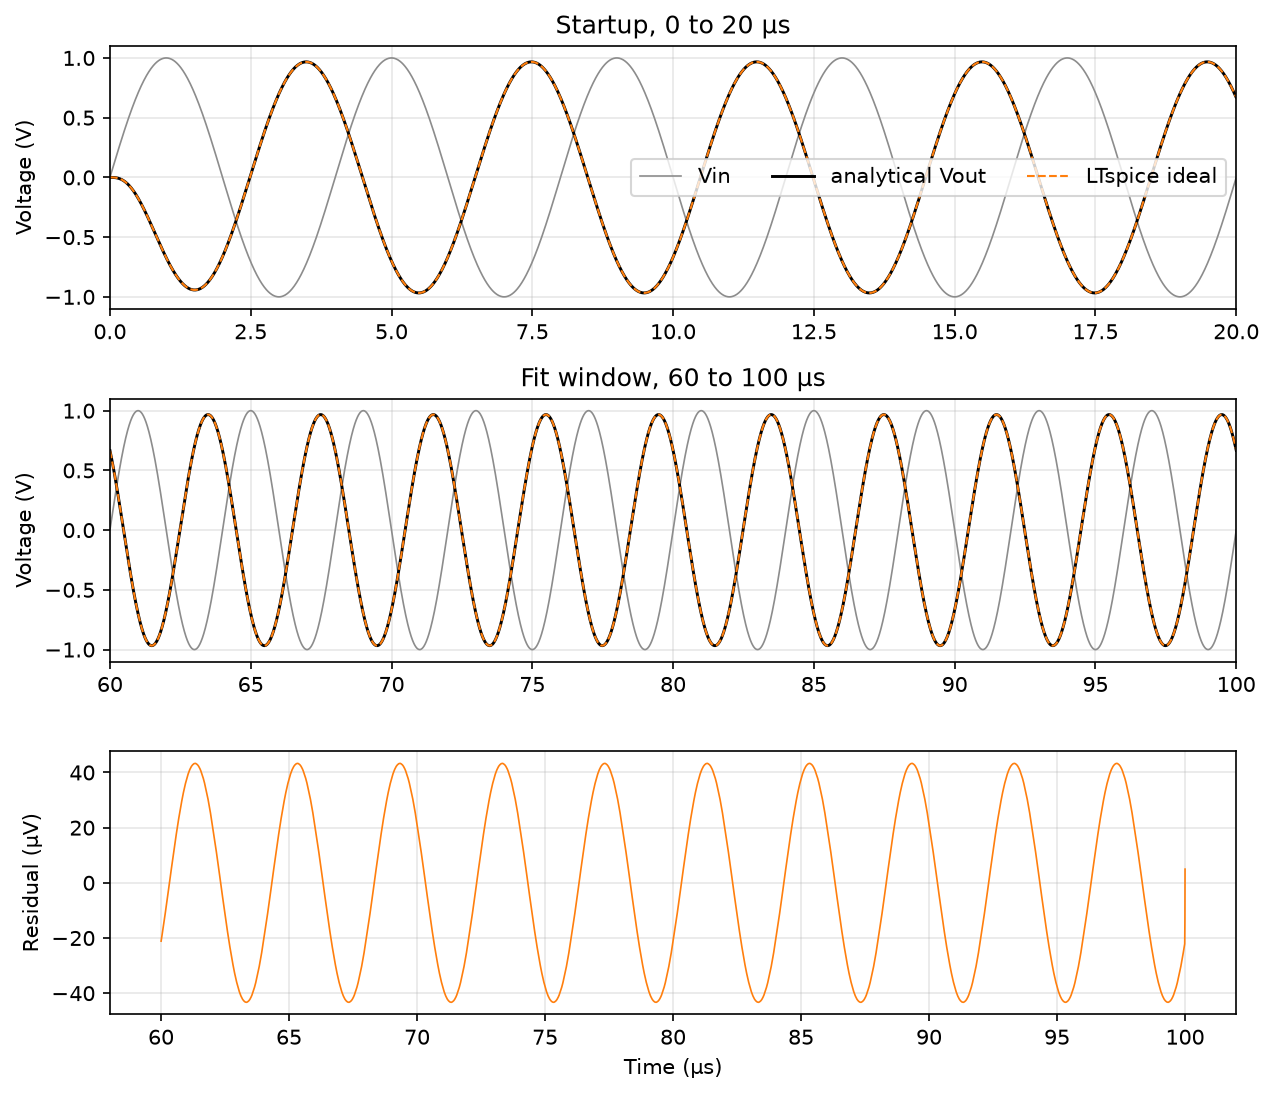

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(8.6, 7.4), sharex=False)
windows = (
    (axes[0], 0.0, 20e-6, "Startup, 0 to 20 µs"),
    (axes[1], 60e-6, 100e-6, "Fit window, 60 to 100 µs"),
)
for ax, t0, t1, label in windows:
    m = (time >= t0) & (time <= t1)
    ax.plot(time[m]*1e6, vin[m], color="0.55", lw=0.8, label="Vin")
    ax.plot(time[m]*1e6, vref[m], "k-", lw=1.4, label="analytical Vout")
    ax.plot(time[m]*1e6, vout[m], "C1--", lw=1.0, label="LTspice ideal")
    ax.set_xlim(t0*1e6, t1*1e6)
    ax.set_ylabel("Voltage (V)")
    ax.set_title(label)
    ax.grid(True, alpha=0.3)
axes[0].legend(frameon=True, ncol=3)
m = time >= 60e-6
axes[2].plot(time[m]*1e6, (vout[m] - vref[m])*1e6, color="C1", lw=0.8)
axes[2].set_xlabel("Time (µs)")
axes[2].set_ylabel("Residual (µV)")
axes[2].grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "03_ltspice_transient.png", dpi=150)
plt.show()
